# TXLA surface temperature from the virtual Icechunk store

Opens `txla_icechunks/` (`/best` group: one continuous hourly series, each hour from the newest forecast run) and maps sea surface temperature (`temp` at the 1 m level).

Run from the `txla/` folder in the `notebook` conda environment. Each map reads one 14 MB chunk (the whole 3-D `temp` field at that hour) from TAMU's server, so a handful of maps is cheap. A long point time series of `temp` is not (see README).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from txla_roms_icechunk.load import open_txla

best = open_txla("best", repo_path="../local-store")
sst = best.temp.isel(Depth=0)      # Depth[0] = 1 m
print(f"{best.sizes['time']} hours: {str(best.time.values[0])[:16]} to {str(best.time.values[-1])[:16]} UTC")
sst

  2026-11-18T20:04:45.668782Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343



2136 hours: 2026-08-23T01:00 to 2026-11-20T00:00 UTC


<xarray.DataArray 'temp' (time: 2136, Y: 190, X: 670)> Size: 1GB
dask.array<getitem, shape=(2136, 190, 670), dtype=float32, chunksize=(1, 190, 670), chunktype=numpy.ndarray>
Coordinates:
  * time                     (time) datetime64[ns] 17kB 2026-08-23T01:00:00 ....
    forecast_reference_time  (time) datetime64[ns] 17kB dask.array<chunksize=(2136,), meta=np.ndarray>
    lead                     (time) timedelta64[s] 17kB dask.array<chunksize=(2136,), meta=np.ndarray>
    lon                      (Y, X) float64 1MB dask.array<chunksize=(190, 670), meta=np.ndarray>
    lat                      (Y, X) float64 1MB dask.array<chunksize=(190, 670), meta=np.ndarray>
    Depth                    float64 8B 1.0
Dimensions without coordinates: Y, X
Attributes:
    long_name:      potential sea water temperature
    standard_name:  sea_water_potential_temperature
    units:          degree_Celsius

## Latest hour in the store

<timed exec>:2: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.


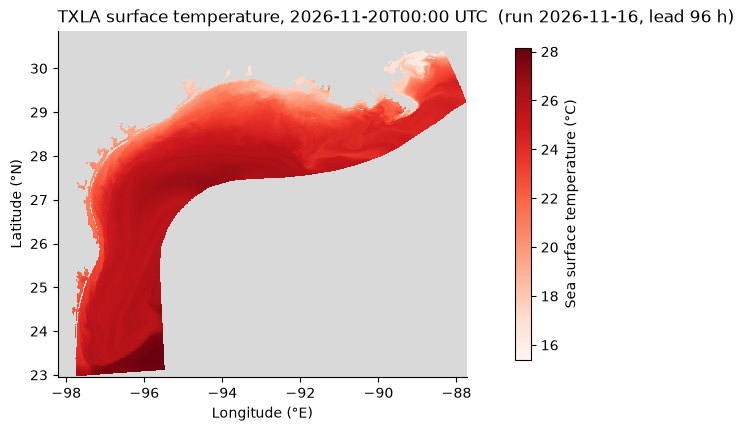

min 15.38  mean 23.73  max 28.15 °C
CPU times: user 400 ms, sys: 404 μs, total: 400 ms
Wall time: 1.28 s


In [8]:
%%time
def plot_map(ax, da, vmin, vmax):
    m = ax.pcolormesh(best.lon, best.lat, da, cmap="Reds", vmin=vmin, vmax=vmax, shading="auto")
    ax.set_facecolor("#d9d9d9")                      # land (NaN) shows as gray
    ax.set_aspect(1 / np.cos(np.deg2rad(27)))        # degrees -> roughly equal km at 27 N
    ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    return m

t = best.time[-1]
field = sst.sel(time=t).load()
run = str(best.forecast_reference_time.sel(time=t).values)[:10]
lead = int(best.lead.sel(time=t) / np.timedelta64(1, "h"))

fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
m = plot_map(ax, field, float(field.min()), float(field.max()))
fig.colorbar(m, ax=ax, label="Sea surface temperature (°C)", shrink=0.9)
ax.set_title(f"TXLA surface temperature, {str(t.values)[:16]} UTC  (run {run}, lead {lead} h)", loc="left")
plt.show()
print(f"min {float(field.min()):.2f}  mean {float(field.mean()):.2f}  max {float(field.max()):.2f} °C")

## Seasonal cooling: noon UTC every four weeks, on one shared color scale (1st–99.5th percentile)

<timed exec>:2: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
<timed exec>:2: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
<timed exec>:2: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
<timed exec>:2: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, 

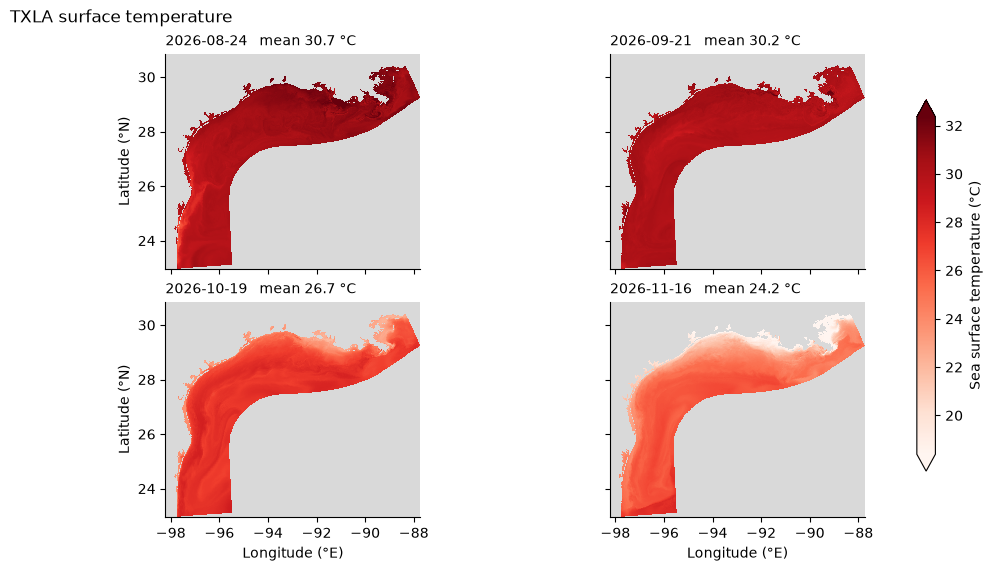

CPU times: user 897 ms, sys: 177 ms, total: 1.07 s
Wall time: 2.09 s


In [9]:
%%time
dates = ["2026-08-24T12:00", "2026-09-21T12:00", "2026-10-19T12:00", "2026-11-16T12:00"]
fields = sst.sel(time=dates).load()
vmin, vmax = np.nanpercentile(fields, [1, 99.5])   # robust: a few nearshore cells run hot

fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), layout="constrained", sharex=True, sharey=True)
for ax, d in zip(axes.flat, dates):
    m = plot_map(ax, fields.sel(time=d), vmin, vmax)
    ax.set_title(f"{d[:10]}   mean {float(fields.sel(time=d).mean()):.1f} °C", loc="left", fontsize=10)
    ax.label_outer()
fig.colorbar(m, ax=axes, label="Sea surface temperature (°C)", shrink=0.8, extend="both")
fig.suptitle("TXLA surface temperature", x=0.02, ha="left")
plt.show()